# Percolation: when does it flow through?

*Beyond the scriptum — an application.*

---

A lattice of pipes, each of which is independently open with probability $p$. Does water flow from
left to right?

Below a certain value of $p$ practically never, above it practically always — and the transition
between the two is the sharper, the larger the lattice we take. In an infinite lattice it is
**perfectly sharp**: there is a critical value $p_c$ below which percolation is impossible and above
which it is certain.

This is called a **phase transition** and it is the same thing as in `branching_process`, only in
space instead of in time. The same mathematics describes the spread of a fire in a forest, a failure
in a distribution network, or the seepage of oil through sandstone.

The model has a rare property: for bond percolation on a square lattice

$$p_c = \tfrac12 \qquad \textbf{exactly},$$

which follows from the self-duality of the lattice (Kesten, 1980). So once again we have an exact check
— and on top of that the nicest pictures in the repository.

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def lattice(rows, cols, p):
    '''Random opening of bonds. H[r][c] joins (r,c) and (r,c+1), V[r][c] joins (r,c) and (r+1,c).'''
    H = [[random.random() < p for _ in range(cols - 1)] for _ in range(rows)]
    V = [[random.random() < p for _ in range(cols)] for _ in range(rows - 1)]
    return H, V


def reachable(rows, cols, H, V):
    '''Which nodes are reachable from the left edge (depth-first search).'''
    seen = [[False] * cols for _ in range(rows)]
    stack = []
    for r in range(rows):
        seen[r][0] = True
        stack.append((r, 0))
    while stack:
        r, c = stack.pop()
        for rr, cc, open_ in ((r, c + 1, c < cols - 1 and H[r][c]),
                              (r, c - 1, c > 0 and H[r][c - 1]),
                              (r + 1, c, r < rows - 1 and V[r][c]),
                              (r - 1, c, r > 0 and V[r - 1][c])):
            if open_ and not seen[rr][cc]:
                seen[rr][cc] = True
                stack.append((rr, cc))
    return seen


def percolates(rows, cols, p):
    H, V = lattice(rows, cols, p)
    seen = reachable(rows, cols, H, V)
    return any(seen[r][cols - 1] for r in range(rows))

## 1. What it looks like

First a picture. For three values of $p$ we draw the open bonds and highlight where the water from the
left edge gets to.

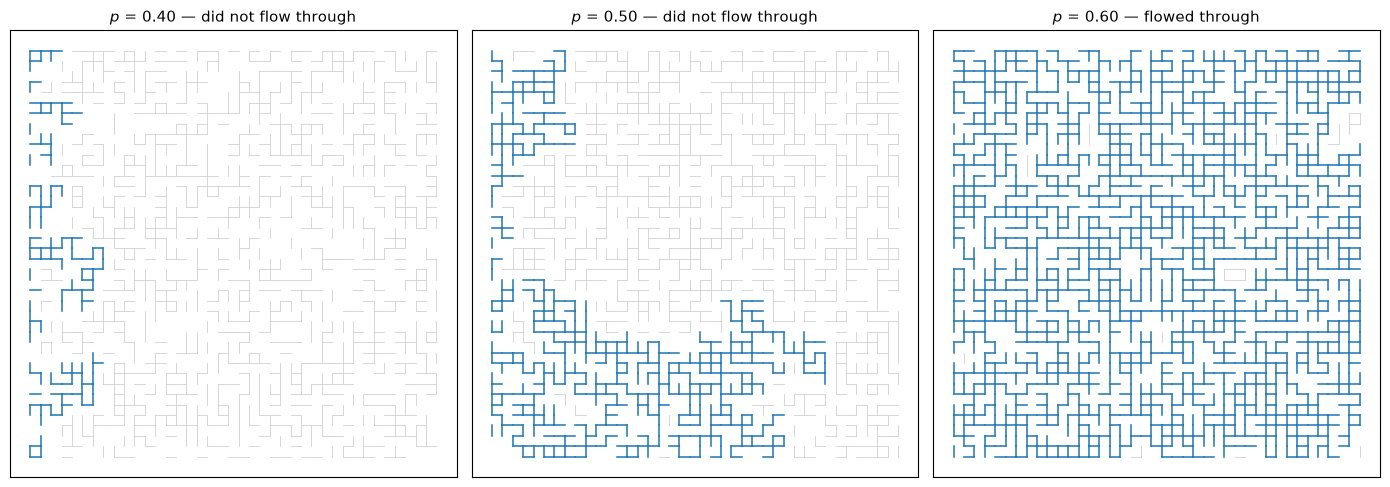

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
L = 40
for ax, p in zip(axes, (0.40, 0.50, 0.60)):
    H, V = lattice(L, L, p)
    seen = reachable(L, L, H, V)
    for r in range(L):
        for c in range(L - 1):
            if H[r][c]:
                wet = seen[r][c] and seen[r][c + 1]
                ax.plot([c, c + 1], [r, r], color="tab:blue" if wet else "0.82",
                        lw=1.1 if wet else 0.6, zorder=2 if wet else 1)
    for r in range(L - 1):
        for c in range(L):
            if V[r][c]:
                wet = seen[r][c] and seen[r + 1][c]
                ax.plot([c, c], [r, r + 1], color="tab:blue" if wet else "0.82",
                        lw=1.1 if wet else 0.6, zorder=2 if wet else 1)
    leaked = any(seen[r][L - 1] for r in range(L))
    ax.set_title(f"$p$ = {p:.2f} — {'flowed through' if leaked else 'did not flow through'}", fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

On the left the blue region is small and shattered into islands. On the right it forms one large
connected whole that passes right through. In the middle, exactly at the critical point, it is on the
edge — and it is precisely there that the pattern has that characteristic "holey" structure at all
scales at once.

## 2. The transition sharpens with the size

Now we measure it. For several sizes $L$ we sweep $p$ and compute the fraction of lattices through
which water flows.

    L         square L x L       rectangle L x (L+1)


    8       0.5673 +- 0.0046           0.4978 +- 0.0046


   16       0.5236 +- 0.0046           0.4992 +- 0.0046


   32       0.5127 +- 0.0046           0.4972 +- 0.0046


   64       0.5252 +- 0.0079           0.5082 +- 0.0079


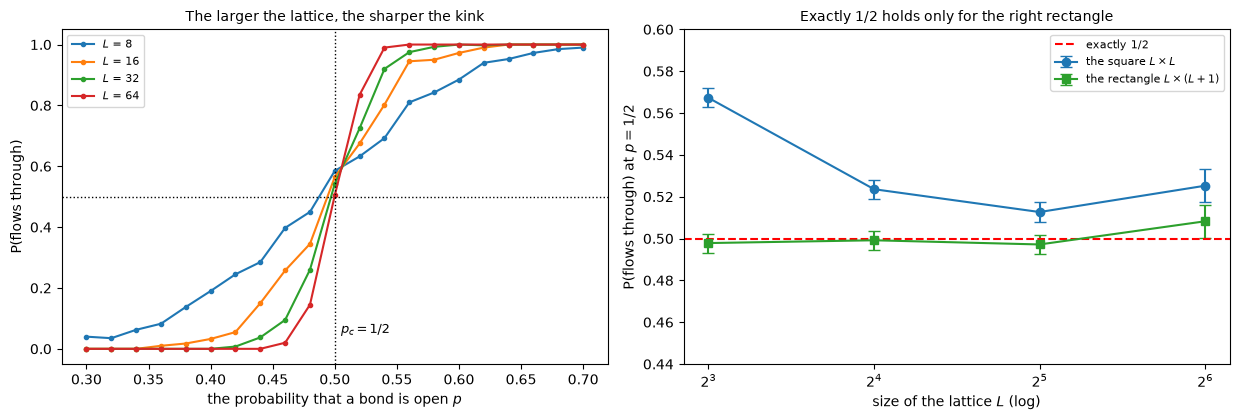


On the square P(flows through) comes out above 1/2 and falls towards it only as L grows —
the square favours the horizontal direction. Self-duality gives EXACTLY 1/2
for a rectangle one column wider, and there it holds for every L separately.


In [3]:
def curve(L, grid, M_=400):
    return [sum(percolates(L, L, p) for _ in range(M_)) / M_ for p in grid]


grid = [0.30 + 0.02 * i for i in range(21)]
sizes = (8, 16, 32, 64)
curves = {L: curve(L, grid, 400 if L <= 32 else 200) for L in sizes}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
ax = axes[0]
for L in sizes:
    ax.plot(grid, curves[L], "o-", ms=3, label=f"$L$ = {L}")
ax.axvline(0.5, color="k", ls=":", lw=1)
ax.axhline(0.5, color="k", ls=":", lw=1)
ax.text(0.505, 0.05, "$p_c = 1/2$", fontsize=9)
ax.set_xlabel("the probability that a bond is open $p$")
ax.set_ylabel("P(flows through)")
ax.set_title("The larger the lattice, the sharper the kink", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
print(f"{'L':>5s} {'square L x L':>20s} {'rectangle L x (L+1)':>25s}")
square, rectangle = [], []
for L in sizes:
    M_ = 12_000 if L <= 32 else 4_000
    fs = sum(percolates(L, L, 0.5) for _ in range(M_)) / M_
    fr = sum(percolates(L, L + 1, 0.5) for _ in range(M_)) / M_
    se = math.sqrt(0.25 / M_)
    square.append((fs, se)); rectangle.append((fr, se))
    print(f"{L:>5d} {fs:>12.4f} +- {se:.4f} {fr:>16.4f} +- {se:.4f}")

ax.errorbar(sizes, [f for f, _ in square], yerr=[s for _, s in square],
            fmt="o-", capsize=4, label="the square $L \\times L$")
ax.errorbar(sizes, [f for f, _ in rectangle], yerr=[s for _, s in rectangle],
            fmt="s-", capsize=4, color="tab:green", label="the rectangle $L \\times (L+1)$")
ax.axhline(0.5, color="r", ls="--", label="exactly 1/2")
ax.set_xscale("log", base=2)
ax.set_xlabel("size of the lattice $L$ (log)")
ax.set_ylabel("P(flows through) at $p = 1/2$")
ax.set_ylim(0.44, 0.60)
ax.set_title("Exactly 1/2 holds only for the right rectangle", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("\nOn the square P(flows through) comes out above 1/2 and falls towards it only as L grows —")
print("the square favours the horizontal direction. Self-duality gives EXACTLY 1/2")
print("for a rectangle one column wider, and there it holds for every L separately.")

The left-hand plot is the phase transition as it is being born: for small lattices a smooth curve,
for large ones almost a step. In the limit $L \to \infty$ it would be a true jump from zero to one at
the point $p_c = 1/2$.

The right-hand plot is the exact check — and it is instructive how easily it can be missed.
Self-duality really does give **exactly $1/2$**, but it holds for a rectangle of size
$L \times (L+1)$, i.e. one column wider than it is high. On a square the horizontal direction is
slightly favoured, so it comes out above $1/2$ and falls to one half only as $L$ grows.

The green series in the plot stands at $1/2$ for each $L$ separately, the blue one only approaches it.
Had we measured on the square alone, we might have concluded from those 0.52 that $p_c$ lies slightly
elsewhere.

## 3. How large is the largest cluster

A second view of the same thing: instead of "does it flow through?" let us ask what part of the
lattice belongs to the **largest connected component**. Below $p_c$ all the clusters are small, above
$p_c$ there exists a single giant one that swallows a finite fraction of the lattice.

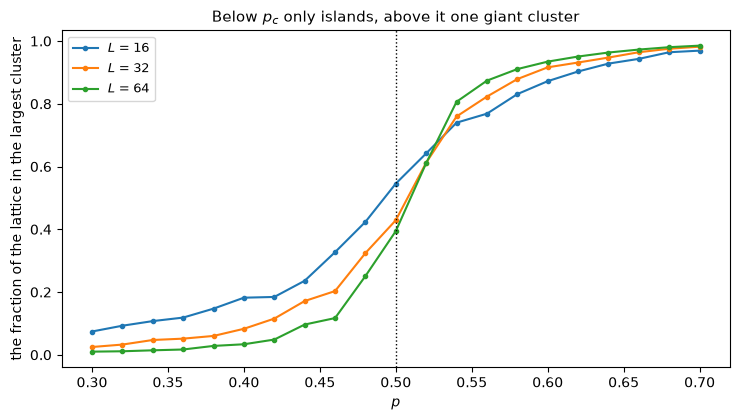

In [4]:
def largest_cluster(L, p):
    '''The fraction of nodes in the largest connected component.'''
    H, V = lattice(L, L, p)
    seen = [[False] * L for _ in range(L)]
    largest = 0
    for r0 in range(L):
        for c0 in range(L):
            if seen[r0][c0]:
                continue
            size, stack = 0, [(r0, c0)]
            seen[r0][c0] = True
            while stack:
                r, c = stack.pop()
                size += 1
                for rr, cc, open_ in ((r, c + 1, c < L - 1 and H[r][c]),
                                      (r, c - 1, c > 0 and H[r][c - 1]),
                                      (r + 1, c, r < L - 1 and V[r][c]),
                                      (r - 1, c, r > 0 and V[r - 1][c])):
                    if open_ and not seen[rr][cc]:
                        seen[rr][cc] = True
                        stack.append((rr, cc))
            largest = max(largest, size)
    return largest / (L * L)


fig, ax = plt.subplots(figsize=(7.5, 4.3))
for L, color in ((16, "tab:blue"), (32, "tab:orange"), (64, "tab:green")):
    fractions = [sum(largest_cluster(L, p) for _ in range(30 if L < 64 else 12)) / (30 if L < 64 else 12)
                 for p in grid]
    ax.plot(grid, fractions, "o-", ms=3, color=color, label=f"$L$ = {L}")
ax.axvline(0.5, color="k", ls=":", lw=1)
ax.set_xlabel("$p$")
ax.set_ylabel("the fraction of the lattice in the largest cluster")
ax.set_title("Below $p_c$ only islands, above it one giant cluster", fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## Summary

| Concept | What to remember |
|-------|------------------|
| Percolation | every bond open with probability $p$, independently |
| The phase transition | below $p_c$ percolation practically impossible, above it practically certain |
| $p_c = 1/2$ | for bond percolation on a square lattice **exactly**, from self-duality |
| The exact check | at $p = 1/2$ P(percolation) = 1/2 for every $L$ — but only on an $L\times(L+1)$ rectangle |
| A finite lattice | the transition is smeared; it sharpens as $L$ grows |
| The largest cluster | below $p_c$ only islands, above it one giant one |
| Where it is useful | the spread of a fire, failures in a network, seepage through rock, the resilience of materials |

The connection to the other notebooks: it is the same phase transition as in the branching process,
only in space. There the mean number of offspring $R_0$ decided, here the density of open bonds $p$ —
and in both cases the behaviour breaks at a single point.

### Try it yourself

1. Do **site** percolation (the nodes open, not the bonds). The critical value is no longer 1/2 —
   measure it. (It comes out around 0.5927, and no closed formula is known for it.)
2. Try a triangular lattice, where site percolation has exactly $p_c = 1/2$ again.
3. Measure how fast the transition sharpens: the width of the transition region falls like
   $L^{-1/\nu}$. Estimate $\nu$ (the true value is 4/3).
4. In three dimensions $p_c \approx 0.2488$. Verify that in space far fewer open bonds are needed for
   percolation, and explain why.
5. Instead of "does it flow through?" track **the length of the shortest path** across. How does it
   behave near $p_c$?
6. A fire model: ignite the left edge and watch how the fire spreads in time. How many steps does it
   take to get through, as a function of $p$?